# Vaccination associations and triangular heatmaps

Explore the five groups in `documentation/hypothesis.md` using original observed training responses. This notebook reproduces our vaccination-rate analysis and triangular heatmaps within the team repository. It complements the existing cleaning notebooks and does not change raw data, processed data, or `src/clean.py`.

Run all cells in order. Requirements: Python, pandas and NumPy; IPython supplies inline previews in Jupyter. Outputs go to `reports/`, with images in `reports/figures/`. Test respondents have no observed vaccination outcomes and are not included.

These results describe associations, not causal effects or independent model importance.


In [1]:
from pathlib import Path
import re
import json
import html
import numpy as np
import pandas as pd

# Find this repository from its root or notebook directory.
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'data_sets/training_set_features.csv').exists()
             and (p / 'src/clean.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter in this repository or its notebook folder.')
OUT = ROOT / 'reports'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(ROOT / 'data_sets/training_set_features.csv')
labels = pd.read_csv(ROOT / 'data_sets/training_set_labels.csv')
targets = ['h1n1_vaccine', 'seasonal_vaccine']
assert train.respondent_id.is_unique and labels.respondent_id.is_unique
assert set(train.respondent_id) == set(labels.respondent_id)
data = train.merge(labels, on='respondent_id', validate='one_to_one')
groups = {}
for section in re.split(r'^## ', (ROOT / 'documentation/hypothesis.md').read_text(), flags=re.M)[1:]:
    title = section.splitlines()[0]
    groups[title] = [c for c in re.findall(r'`([^`]+)`', section)
                     if c in train and c != 'respondent_id']
assigned = {c for cols in groups.values() for c in cols}
groups['Additional predictors outside the five hypotheses'] = [c for c in train if c != 'respondent_id' and c not in assigned]
assert len(assigned) > 0
print(f'{len(data):,} respondents; {train.shape[1]-1} predictors; two outcomes.')
print('Overall vaccination rates (%):', labels[targets].mean().mul(100).round(2).to_dict())
missing = pd.DataFrame({'missing_count': train.isna().sum(), 'missing_percent': train.isna().mean()*100}).sort_values('missing_percent', ascending=False)
missing.to_csv(OUT / 'original_missing_values.csv')
print(missing.head(7).round(2).to_string())


26,707 respondents; 35 predictors; two outcomes.
Overall vaccination rates (%): {'h1n1_vaccine': 21.25, 'seasonal_vaccine': 46.56}
                       missing_count  missing_percent
employment_occupation          13470            50.44
employment_industry            13330            49.91
health_insurance               12274            45.96
income_poverty                  4423            16.56
doctor_recc_h1n1                2160             8.09
doctor_recc_seasonal            2160             8.09
rent_or_own                     2042             7.65


## Category vaccination rates and feature associations

Missing answers are excluded separately for each feature, rather than filled for this descriptive analysis. Category rates include sample sizes and Wilson 95% intervals. Cramér’s V measures the strength of each feature’s unadjusted association with vaccination; it does not represent a joint group effect.

Numeric categories appear in ascending order. Binary codes are 0 = no and 1 = yes. Other numbers are survey scores or capped household counts; their meaning depends on the column.


In [2]:
rates = []
associations = []
for version, frame in [('observed', train)]:
    data = frame.merge(labels, on='respondent_id', validate='one_to_one')
    for group, cols in groups.items():
        for c in cols:
            for target in targets:
                subset = data.dropna(subset=[c, target])
                for category, part in subset.groupby(c, sort=False):
                    n = len(part); k = int(part[target].sum()); p = k/n
                    # Wilson 95% interval, descriptive rather than a multiple-testing claim.
                    z=1.959963984540054
                    center=(p+z*z/(2*n))/(1+z*z/n)
                    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
                    rates.append(dict(version=version, group=group, feature=c, target=target,
                                      category=category, n=n, vaccinated=k, rate_percent=100*p,
                                      ci95_low_percent=100*(center-half), ci95_high_percent=100*(center+half)))
                tab = pd.crosstab(subset[c], subset[target]).reindex(columns=[0,1], fill_value=0)
                a=tab.to_numpy(); expected=np.outer(a.sum(axis=1), a.sum(axis=0))/a.sum()
                chi=((a-expected)**2/expected).sum()
                v=np.sqrt(chi/a.sum()) if len(a)>1 else 0
                associations.append(dict(version=version, group=group, feature=c, target=target, n=len(subset), cramers_v=v))
rates=pd.DataFrame(rates); assoc=pd.DataFrame(associations)
rates.to_csv(OUT / 'vaccination_rates_by_category.csv', index=False)
assoc.to_csv(OUT / 'feature_associations.csv', index=False)

print('Saved category rates, confidence intervals and individual feature associations.')


Saved category rates, confidence intervals and individual feature associations.


## Main findings across the five hypotheses

| Group | Findings from observed responses |
|---|---|
| Demographics | Seasonal uptake is 28.5% for ages 18–34 and 67.4% for 65+. H1N1 age differences are much smaller and are not steadily increasing. |
| Socioeconomic circumstances | Seasonal uptake is 53.8% among insured respondents versus 22.9% among uninsured respondents; insurance status is missing for 46%. |
| Doctor recommendations | H1N1 uptake is 53.2% with a matching recommendation versus 13.6% without. Seasonal uptake is 73.8% versus 34.6%. |
| Health literacy and behaviour | Perceived disease risk and vaccine effectiveness opinions have stronger associations than most individual hygiene behaviours. |
| Medical conditions | Seasonal uptake is 60.4% with a chronic condition versus 41.5% without; H1N1 is 27.5% versus 18.9%. |

These are individual, unadjusted comparisons. The groups overlap in the information they capture. Missing responses may be systematic; no adjusted causal analysis or formal significance tests were performed.


In [3]:
body=['<h1>Vaccination rates across the five feature groups</h1>',
      '<p>Descriptive analysis of 26,707 training respondents. Overall uptake: H1N1 21.2%; seasonal flu 46.6%. Test data have no observed outcomes and are excluded. Associations do not establish causation or independent effects.</p>',
      '<p>Charts use observed values only, excluding missing values separately for each feature. Bars show vaccination percentages; counts and Wilson 95% intervals are in vaccination_rates_by_category.csv. Cramér’s V measures the strength of each individual feature’s unadjusted association (0 to 1); it is not a joint group effect. Groups have different numbers of features, so their maxima should not be treated as a group ranking.</p>']
body.append('''<h2>Summary of the five hypotheses</h2>
<table><tr><th>Group</th><th>Observed association with vaccination</th></tr>
<tr><td>Demographics</td><td>Age is particularly associated with seasonal vaccination: 28.5% for ages 18–34 versus 67.4% for ages 65+. Demographic associations with H1N1 are smaller; education has the largest association within this group.</td></tr>
<tr><td>Socioeconomic circumstances</td><td>Among respondents reporting insurance status, insured people have higher uptake: H1N1 31.8% versus 14.7%, seasonal 53.8% versus 22.9%. Insurance is missing for 46%, limiting generalisation. Seasonal uptake is 49.7% above $75,000 income versus 36.3% below poverty.</td></tr>
<tr><td>Doctor recommendations</td><td>Large differences for the corresponding vaccine: H1N1 53.2% with a recommendation versus 13.6% without; seasonal 73.8% versus 34.6%.</td></tr>
<tr><td>Health literacy and behaviour</td><td>Vaccine effectiveness opinions and perceived disease risk have the strongest associations within this group. H1N1 uptake is 51.1% at risk rating 5 versus 8.8% at rating 1; seasonal uptake is 74.5% versus 20.9% for its corresponding risk ratings. H1N1 uptake is 27.8% at knowledge score 2 versus 14.4% at score 0. Individual hygiene behaviours generally have smaller associations than these opinion measures.</td></tr>
<tr><td>Medical conditions</td><td>Respondents reporting a chronic condition have higher uptake: H1N1 27.5% versus 18.9%, seasonal 60.4% versus 41.5%.</td></tr></table>
<p>All five groups contain features associated with uptake in this sample. These descriptive patterns support further investigation of the hypotheses, but do not confirm causal influence, establish an independent contribution for each group, or imply that every feature matters. Age, access to care and other factors can overlap across groups. Missing responses may be systematic; this summary uses observed responses only. No adjusted model or formal hypothesis significance tests were performed.</p>''')
for group, cols in groups.items():
    body.append(f'<h2>{html.escape(group)}</h2>')
    for c in cols:
        body.append(f'<details><summary>{html.escape(c)}</summary><table><tr><th>Category</th><th>People</th><th>H1N1</th><th>Seasonal</th></tr>')
        subset=rates[(rates.version=='observed') & (rates.feature==c)]
        categories = list(subset.category.unique())
        def category_order(value):
            try:
                return (0, float(value))
            except (TypeError, ValueError):
                return (1, str(value))
        for cat in sorted(categories, key=category_order):
            rr=subset[subset.category==cat].set_index('target')
            cells=''.join(f'<td><span class="bar" style="width:{rr.loc[t,"rate_percent"]:.1f}px"></span> {rr.loc[t,"rate_percent"]:.1f}%</td>' for t in targets)
            body.append(f'<tr><td>{html.escape(str(cat))}</td><td>{int(rr.iloc[0]["n"]):,}</td>{cells}</tr>')
        body.append('</table></details>')
body.append('<h2>Missing values and interpretation</h2><p>This analysis uses original observed training responses only. Missing answers are excluded separately for each feature or pair. No imputation is performed and the team cleaning pipeline is unchanged. Industry and occupation may be not applicable for non-employed respondents. Undefined pairwise associations are shown as N/A when a variable has only one observed category in the paired subset. These are unadjusted associations, not causal or independent effects.</p>')
body.append('<p><a href="triangular_heatmaps.html">Open the triangular heatmaps</a></p>')
(OUT / 'vaccination_analysis.html').write_text('<!doctype html><meta charset="utf-8"><title>Vaccination analysis</title><style>body{font:16px system-ui;max-width:1050px;margin:40px auto;padding:20px;color:#203040}table{border-collapse:collapse;width:100%;margin:12px 0}td,th{text-align:left;padding:8px;border-bottom:1px solid #ddd}.bar{display:inline-block;background:#249b9a;height:12px}summary{cursor:pointer;padding:9px;background:#eef4f6;margin:5px 0}</style>'+''.join(body))

print('Saved reports/vaccination_analysis.html')


Saved reports/vaccination_analysis.html


## Triangular association and correlation matrices

**All-feature view:** Cramér’s V for all 35 predictors and both outcomes (37 × 37 underlying matrix). Values run from 0 to 1 and have no positive or negative direction. It treats survey scores and counts as categories; it can be influenced by category counts and sample size.

**Ordered-feature view:** Spearman correlation for 26 ordered or binary predictors and both outcomes (28 × 28 underlying matrix). Positive values indicate increasing uptake or scores together; negative values indicate opposite trends. Age, education and income are ordered explicitly. Unordered text features are excluded. Household counts are capped at 3 or more; adult counts exclude the respondent.

Only the lower triangle is drawn: each pair appears once, with no diagonal of self-comparisons. Labels sit directly above the first visible cell of each column. The last two rows show relationships with vaccination.

**Why two cells are undefined:** among respondents with both employment status and industry/occupation recorded, everyone is employed. Employment status then has no variation, so its association with those fields is undefined. N/A is not zero. Pairwise sample sizes are exported because missingness changes which respondents enter each cell.


In [4]:
columns = [c for cols in groups.values() for c in cols] + targets
ordered = {
    'age_group': ['18 - 34 Years','35 - 44 Years','45 - 54 Years','55 - 64 Years','65+ Years'],
    'education': ['< 12 Years','12 Years','Some College','College Graduate'],
    'income_poverty': ['Below Poverty','<= $75,000, Above Poverty','> $75,000'],
}
numeric = pd.DataFrame(index=data.index)
for c in columns:
    if c in ordered:
        numeric[c] = data[c].map({v:i for i,v in enumerate(ordered[c])})
    elif pd.api.types.is_numeric_dtype(data[c]):
        numeric[c] = data[c]

def matrix(names, mode):
    result=pd.DataFrame(np.nan,index=names,columns=names)
    counts=pd.DataFrame(0,index=names,columns=names)
    for i,a in enumerate(names):
        for j in range(i,len(names)):
            b=names[j]
            source=numeric if mode=='spearman' else data
            mask=source[a].notna() & source[b].notna()
            x=source.loc[mask,a]; y=source.loc[mask,b]; n=int(mask.sum())
            if mode=='spearman':
                value=float(x.rank().corr(y.rank()))
            else:
                table=pd.crosstab(x,y).to_numpy()
                expected=np.outer(table.sum(axis=1),table.sum(axis=0))/n
                chi=np.sum((table-expected)**2/expected)
                denom=min(table.shape)-1
                value=float(np.sqrt(chi/(n*denom))) if denom>0 else float('nan')
            result.iloc[i,j]=result.iloc[j,i]=value
            counts.iloc[i,j]=counts.iloc[j,i]=n
    result.to_csv(OUT/f'square_{mode}_values.csv')
    counts.to_csv(OUT/f'square_{mode}_sample_sizes.csv')
    assert np.allclose(result.to_numpy(),result.to_numpy().T,equal_nan=True)
    assert np.allclose(np.diag(result),1)
    assert result.abs().max().max()<=1.00000001
    return result,counts

def colour(v,mode):
    if not np.isfinite(v):return '#dddddd'
    end=(33,102,172) if mode=='spearman' and v<0 else ((178,24,43) if mode=='spearman' else (8,81,156))
    return '#'+''.join(f'{round(247+(c-247)*min(abs(v),1)):02x}' for c in end)

def make_svg(values,counts,mode,triangular=False):
    names=list(values);cell=38;left=310;top=360;size=len(names)*cell
    width=left+size+30;height=top+size+40
    title='All feature associations — Cramér’s V' if mode=='cramers_v' else 'Ordered feature correlations — Spearman'
    parts=[f'''<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="{title}"><rect width="100%" height="100%" fill="white"/><g font-family="sans-serif" font-size="12" fill="#203040"><text x="20" y="32" font-size="23">{title}</text><text x="20" y="58">Observed training responses; missing values excluded separately for each pair. ID excluded.</text><text x="20" y="80">{'0 = no association; 1 = strongest. No positive or negative direction.' if mode=='cramers_v' else '−1 = negative; 0 = no monotonic relationship; +1 = positive. Unordered features excluded.'}</text><text x="20" y="102">Outcome labels are bold. Diagonal values are 1 by definition. Hover over cells for details.</text>''']
    if triangular:
        parts[0]=parts[0].replace('Diagonal values are 1 by definition.', 'Each pair shown once; diagonal and upper half hidden.')
    for i,c in enumerate(names):
        weight='bold' if c in targets else 'normal'
        parts.append(f'<text x="{left-10}" y="{top+i*cell+24}" text-anchor="end" font-weight="{weight}">{html.escape(c)}</text>')
        # Follow the triangle edge: place each label above its first visible cell.
        label_y = top + (i+1)*cell - 10 if triangular else top - 10
        if not triangular or i < len(names)-1:
            parts.append(f'<text transform="translate({left+i*cell+24},{label_y}) rotate(-60)" font-weight="{weight}">{html.escape(c)}</text>')
        for j,b in enumerate(names):
            if triangular and j >= i:
                continue
            v=float(values.iloc[i,j]);n=int(counts.iloc[i,j]);x=left+j*cell;y=top+i*cell
            tip=f'{c} × {b}: {v:.4f}; paired responses n={n:,}' if np.isfinite(v) else f'{c} × {b}: undefined (no variation in paired responses); n={n:,}'
            cell_text=f'{v:.2f}' if np.isfinite(v) else 'N/A'
            parts.append(f'<g><title>{html.escape(tip)}</title><rect x="{x}" y="{y}" width="{cell}" height="{cell}" fill="{colour(v,mode)}" stroke="white" stroke-width=".6"/><text x="{x+cell/2}" y="{y+24}" text-anchor="middle" fill="{"white" if abs(v)>.6 else "#203040"}" font-size="10">{cell_text}</text></g>')
    # Mark where the two vaccination outcomes start on both axes.
    start=names.index(targets[0])*cell
    if triangular:
        parts.append(f'<path d="M{left},{top+start}h{start} M{left+start},{top+start+cell}v{size-start-cell}" stroke="#dd8a00" stroke-width="3" fill="none"/>')
    else:
        parts.append(f'<path d="M{left+start},{top}v{size} M{left},{top+start}h{size}" stroke="#dd8a00" stroke-width="3" fill="none"/>')
    parts.append('</g></svg>')
    return ''.join(parts)

charts = {}
matrices = {}
for mode, names in [('cramers_v', columns), ('spearman', list(numeric))]:
    values, counts = matrix(names, mode)
    matrices[mode] = (values, counts)
    charts[mode] = make_svg(values, counts, mode, triangular=True)
    (FIGURES / f'triangular_{mode}_heatmap.svg').write_text(charts[mode])
    print(mode, values.shape, 'unique displayed pairs:', len(names)*(len(names)-1)//2)


cramers_v (37, 37) unique displayed pairs: 666
spearman (28, 28) unique displayed pairs: 378


In [5]:
viewer_template = '<!doctype html><html lang="en"><meta charset="utf-8"><title>Triangular vaccination association heatmaps</title>\n<style>body{font:16px system-ui;color:#203040;margin:30px;padding:0 15px}p{max-width:1100px;line-height:1.5}button{font:inherit;padding:10px;margin:5px;cursor:pointer}.chart{overflow:auto;border:1px solid #ddd;max-height:85vh}svg{display:block}a{color:#145b86}.legend{width:450px;height:18px}.ticks{width:450px;display:flex;justify-content:space-between;font-size:13px}#files{margin:16px 0}</style>\n<h1>Triangular heatmaps of predictors and vaccination</h1>\n<p>Both axes contain the same variables. Each cell compares its row feature with its column feature. Grey N/A means an association is undefined in the paired sample.\nThe final two rows are the vaccination outcomes, separated by an orange line. Scroll inside the chart to explore; hover for sample sizes. Only the lower triangle is shown: each pair appears once, and the diagonal of 1s is hidden.</p>\n<button id="all">All features — association strength</button><button id="ordered">Ordered features — correlation and direction</button>\n<p id="description"></p><div class="legend" id="legend"></div><div class="ticks" id="ticks"></div>\n<div id="files"></div><div class="chart" id="chart"></div>\n<p><b>How to use them:</b> inspect the final two rows to compare each predictor’s association with vaccination. Inspect other cells for overlapping information between predictors. A strong association between two predictors does not automatically mean either should be removed; compare model performance when considering removal.</p>\n<p><b>Methods:</b> the all-feature view uses standard, uncorrected Cramér’s V, treating survey answers and capped counts as categories. This supports nominal categories as well as ordered ones, but discards order and direction. V can be inflated by category counts and sample size. The direction view uses pairwise Spearman correlation with average ranks for tied responses. Age, education and income follow their natural order; remaining numeric survey answers use their numeric codes. Missing values are excluded separately for every pair, so cell sample sizes differ and these matrices need not be positive semidefinite.</p>\n<p>Spearman excludes unordered categories: race, sex, marital status, housing tenure, employment status, region, urbanicity, industry and occupation. Household counts are capped at 3 or more; adults excludes the respondent. Opinion scores follow the original survey scale; a higher score means greater endorsement of that specific opinion, including concerns about vaccine illness.</p>\n<p><b>Limits:</b> these are unadjusted associations, not causal effects or independent importance. Employment fields have about 50% missing values and insurance 46%, which limits generalisation. No imputed responses enter either matrix. Use held-out model evaluation to assess additional predictive contributions.</p>\n<p><a href="vaccination_analysis.html">Full analysis</a></p>\n<script>\nconst charts=CHART_DATA;\nfunction show(mode){document.getElementById(\'chart\').innerHTML=charts[mode];document.getElementById(\'description\').textContent=mode===\'cramers_v\'?\'37 × 37: all 35 predictors plus both outcomes. Darker blue means a stronger association. There is no positive or negative direction.\':\'28 × 28: 26 ordered or binary predictors plus both outcomes. Red means a positive correlation; blue means negative; pale cells indicate values near zero.\';document.getElementById(\'legend\').style.background=mode===\'cramers_v\'?\'linear-gradient(to right,#f7f7f7,#08519c)\':\'linear-gradient(to right,#2166ac,#f7f7f7,#b2182b)\';document.getElementById(\'ticks\').innerHTML=mode===\'cramers_v\'?\'<span>0 · weaker</span><span>1 · stronger</span>\':\'<span>−1</span><span>0</span><span>+1</span>\';document.getElementById(\'files\').innerHTML=`<a href="figures/triangular_${mode}_heatmap.svg" download>Download SVG</a> · <a href="square_${mode}_values.csv">Download matrix CSV</a> · <a href="square_${mode}_sample_sizes.csv">Download sample sizes</a>`;}\ndocument.getElementById(\'all\').onclick=()=>show(\'cramers_v\');document.getElementById(\'ordered\').onclick=()=>show(\'spearman\');show(\'cramers_v\');\n</script></html>'
viewer = viewer_template.replace('const charts=CHART_DATA;', 'const charts=' + json.dumps(charts) + ';')
(OUT / 'triangular_heatmaps.html').write_text(viewer)
print('Saved reports/triangular_heatmaps.html and reports/figures/*.svg')


Saved reports/triangular_heatmaps.html and reports/figures/*.svg


Open reports/triangular_heatmaps.html to see the heatmaps.


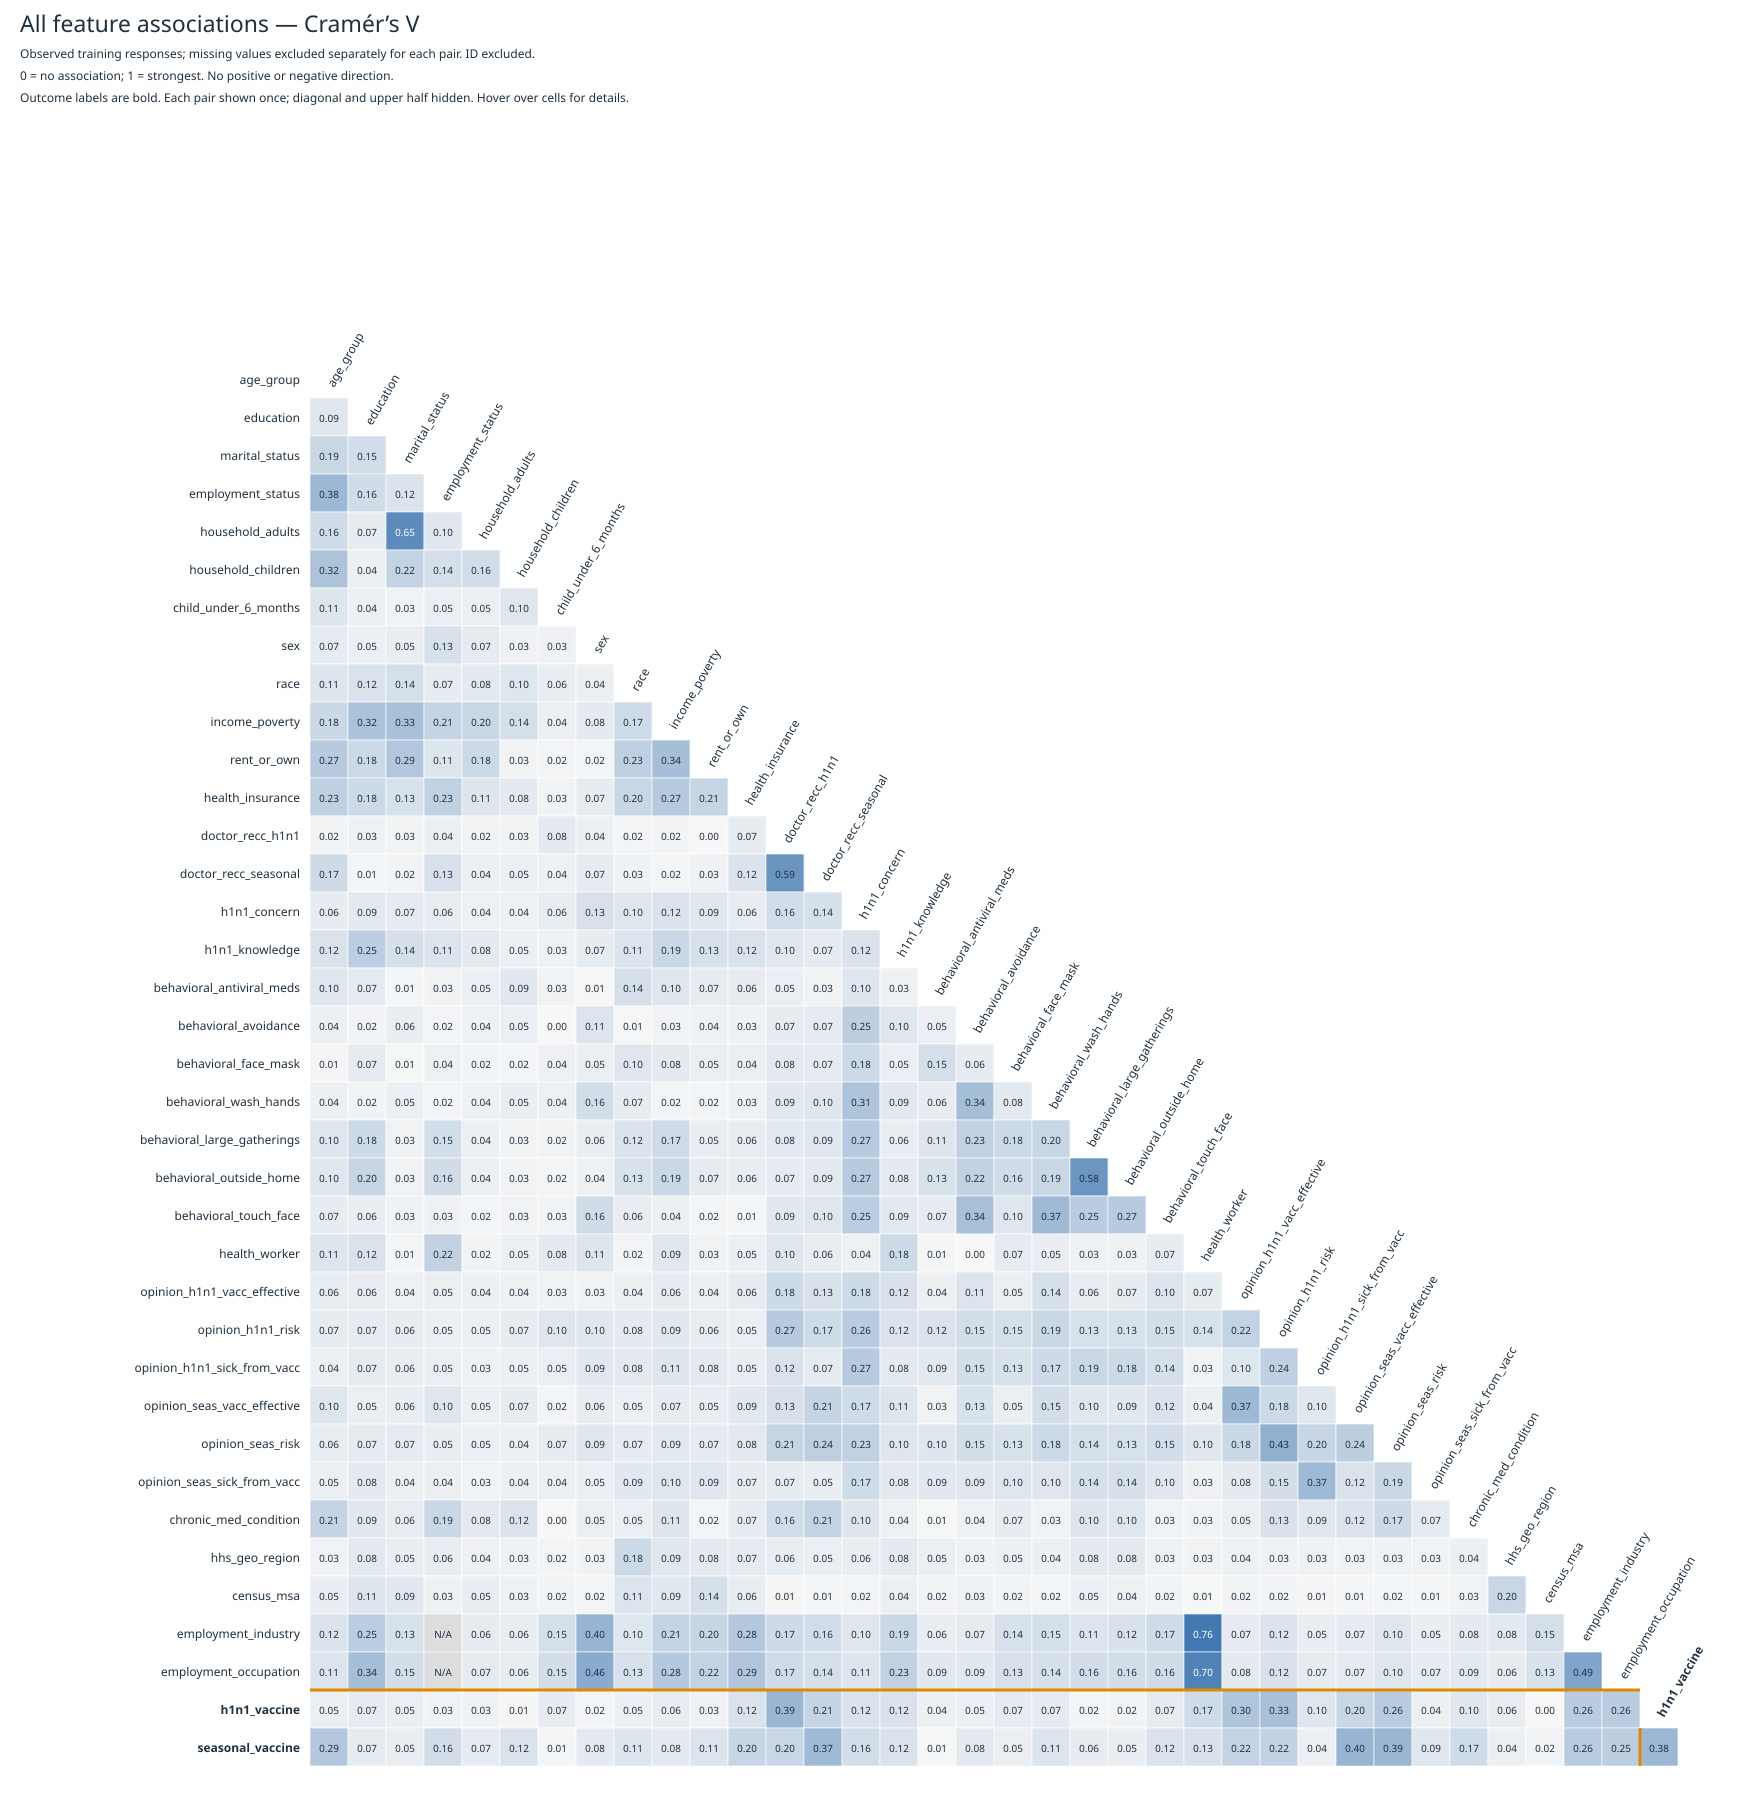

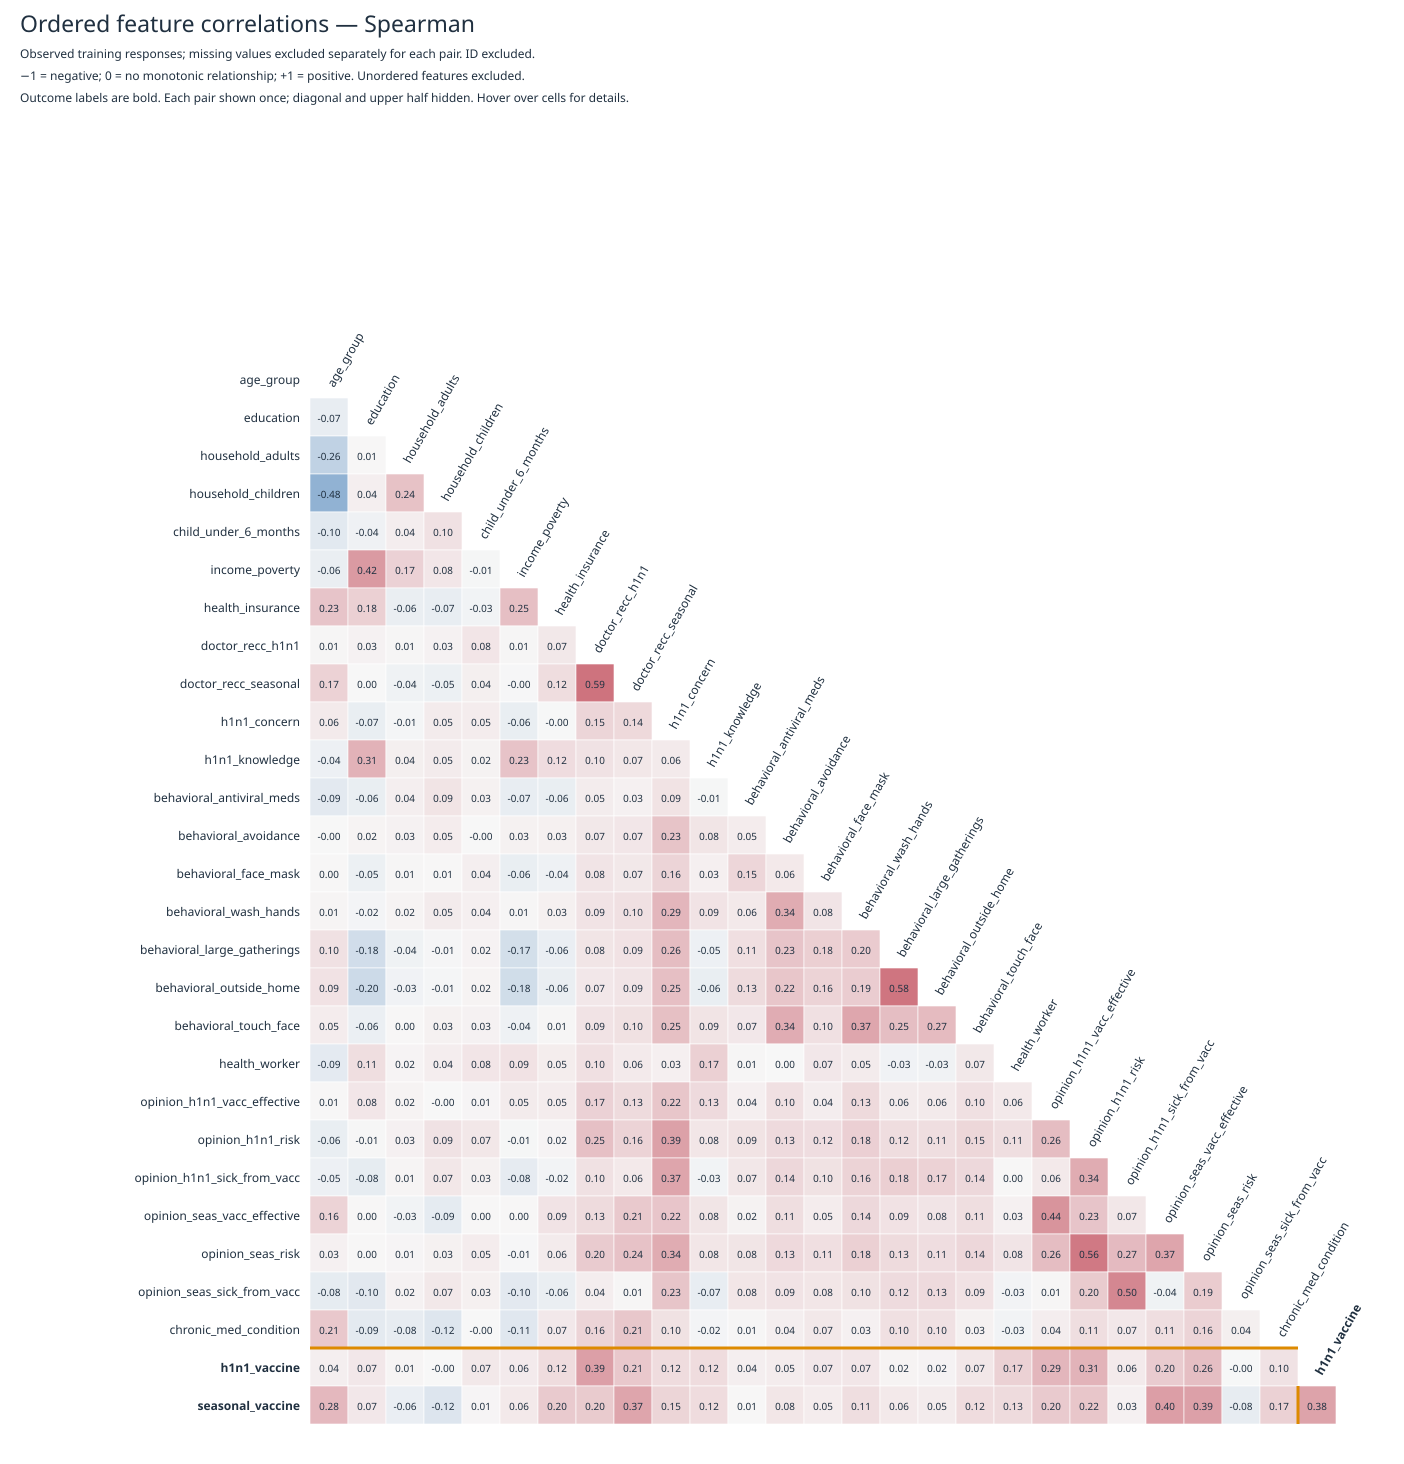

In [6]:
# Inline previews; standalone HTML provides scrolling and download links.
try:
    from IPython.display import SVG, display
except ImportError:
    print('Open reports/triangular_heatmaps.html to see the heatmaps.')
else:
    for mode in ['cramers_v', 'spearman']:
        display(SVG(filename=str(FIGURES / f'triangular_{mode}_heatmap.svg')))


## Verify outputs and explore the reports

- [Vaccination analysis and five hypothesis summary](../reports/vaccination_analysis.html)
- [Triangular heatmaps](../reports/triangular_heatmaps.html)
- [Category rates and confidence intervals](../reports/vaccination_rates_by_category.csv)
- [Original missing-value counts](../reports/original_missing_values.csv)
- [All-feature matrix](../reports/square_cramers_v_values.csv)
- [Ordered-feature matrix](../reports/square_spearman_values.csv)

HTML files can be opened directly in a browser. The underlying square CSVs retain their diagonal and symmetry for reuse, while the figures hide duplicate pairs and diagonals. Undefined associations remain empty in CSVs and appear as N/A in the figures.


In [7]:
import xml.etree.ElementTree as ET
for mode, (values, counts) in matrices.items():
    assert np.allclose(values.to_numpy(), values.to_numpy().T, equal_nan=True)
    assert np.allclose(np.diag(values), 1)
    assert values.abs().max().max() <= 1.00000001
    svg = ET.fromstring(charts[mode])
    pairs = svg.findall('.//{http://www.w3.org/2000/svg}title')
    assert len(pairs) == len(values)*(len(values)-1)//2
    print(mode, ': symmetry, diagonal and triangular cell count verified')
for c in ['employment_industry', 'employment_occupation']:
    assert pd.isna(matrices['cramers_v'][0].loc['employment_status', c])
assert len(train) == len(data) and train.shape[1] == 36
print('Original data retained; no cleaned datasets were created by this notebook.')


cramers_v : symmetry, diagonal and triangular cell count verified
spearman : symmetry, diagonal and triangular cell count verified
Original data retained; no cleaned datasets were created by this notebook.
